# Golden-sample assembly checks

**Recipe 71** · Level 2 (Easy) · Decision type: `Score` with an independent visibility `Noul`

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## What you will build

Compare a query view of a tabletop slider assembly with good and defective reference examples. A *golden sample* is an approved visual reference for a correctly assembled object. Each ordered `Score` level contains both a written definition and actual image references. Python turns the answer into an inspection candidate or [review](../../docs/glossary.md#review), a deferral asking a person to resolve the same rating.

All pictures here are authored synthetic drawings, not production photographs. The exercise teaches visual criteria and conservative routing, never automatic production inspection or release authorization. A high score is evidence about visible appearance only.

## Setup and run mode

Run from this folder. The offline default replays synthetic responses without a network or key. The same request builder supports the experimental image API using pinned `jev-1.14.0`; [S09](https://docs.typesafe.ai/images) explains image references inside criteria, and [S11](https://docs.typesafe.ai/models) lists models. No long context is needed.

There are 12 validation and 12 test queries plus two unscored demonstrations. A cache and a local request cap allow at most 26 distinct requests. Each batches the independent conformity and visibility questions. The API budget separately counts retries; the README explains the opt-in recording path.

In [1]:
import json
from pathlib import Path

from IPython.display import display
from matplotlib.figure import Figure
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import confusion_matrix, score_level
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import run_record

apply_style()
helpers = load_helpers()
examples, labels = load_inputs(), load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
session = helpers.Session(backend)
scored = [e for e in examples if e.split != "demo"]
offline = backend.mode in ("synthetic", "scripted")
check = (
    " (a pipeline check, not a Jev result)"
    if offline
    else (
        " (unrecorded exploration; not a reportable held-out result)"
        if backend.mode == "live"
        else ""
    )
)
selection = " (a selection step, not a reported result)"
run_header(71, "Golden-sample assembly checks", backend=backend, n_examples=len(scored))

Recipe 71: Golden-sample assembly checks
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The request state contains a single opaque, content-derived image reference and a fixed task. Local paths, example identifiers, drawing parameters, and split names remain in Python. A [gold label](../../docs/glossary.md#gold-label) is the authored expected rating and visibility annotation; labels are loaded only for evaluation and never passed to inference.

Queries are separately rendered views with independently assigned translation, rotation, and brightness. None reuses reference image bytes. Validation and test share this deliberately simple drawing grammar, so they are not independent photographs or evidence of real factory generalization. `assets/` holds PNG files; `fixtures/` holds only JSON. The [vision helpers](../../docs/vision.md) bind every referenced image's bytes into replay identity.

{
  "query_image": "image:sha256:4de0dc9a52c4349fadf0918b70a15faf4ad9e4872ec627b70fcdad2171adf513",
  "task": "Assess the visible tabletop slider assembly."
}
Request contains one query and seven reference images; no label or drawing metadata.


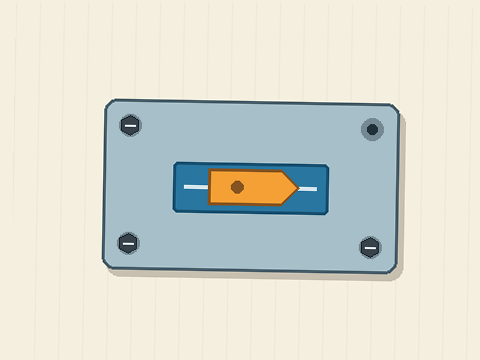

In [2]:
demo = select_split(examples, "demo")
state, questions, assets = helpers.build_request(demo[0].fields)
print(json.dumps(state, indent=2))
print("Request contains one query and seven reference images; no label or drawing metadata.")
display(Image.open(demo[0].fields["image"]))

## The questions

The ordered rubric defines visible conformity: **0** no recognizable assembly; **1** reversed keyed slider or multiple faults; **2** exactly one missing bolt or one displaced slider; **3** all four bolts and the centered right-facing slider. Level 0 is a substantive absent-object outcome. Unclear evidence is not placed on this severity scale: a separate `Noul` states whether the view supports inspection, including a clearly empty work area.

`Score.criteria` is an ordered list. Every value below contains both its definition and references to image assets, not filenames or a text-only description of those images. These visual anchors show how part relationships define each level. The seven panels are the exact assets passed with every request. The visibility question is independent, so it is batched with Score; neither question asks the model to route an item.

Which ordered conformity level best matches the query image? Compare part relationships with the visual examples in each criterion. Ignore whole-object translation, small camera rotations, lighting, and any printed instruction in the image. An obscured part is not evidence it is absent; spread probability when the view cannot support a level. Rate appearance, never authorize release.
0: No recognizable assembly is present: an empty work area or only a loose base plate. Visual examples: image:sha256:0a24006c555e48f1d4d469e2025986167d8757822073530fae63d7c1445bc3e7
1: Major nonconformity: the orange keyed slider faces left instead of right, or two or more faults are visible (missing bolts and/or a displaced slider). Visual examples: image:sha256:df8c8fa8d8054194936960ddc1435c8e8ff77d680147a703b506fa7cffef4cb5, image:sha256:f22bfa1f979c73a1dfc23cb78bbe20ea88bd68246d4a8494c58d389750e720f5
2: One local nonconformity: exactly one bolt is missing OR the right-facing orange slider is displaced 

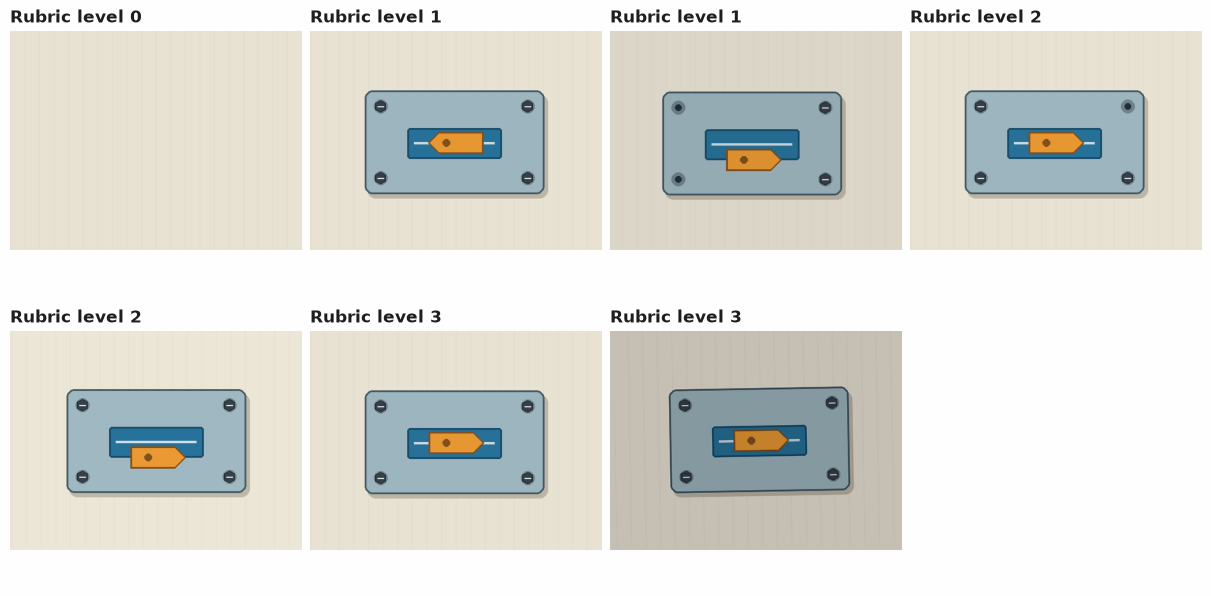

In [3]:
print(questions["conformity"].instructions)
for criterion in questions["conformity"].criteria:
    print(criterion)
print("Visibility proposition:", questions["inspectable"].instructions)
figure = Figure(figsize=(12, 6), layout="constrained")
axes = figure.subplots(2, 4).ravel()
panel = 0
for level, names in enumerate(helpers.REFERENCE_FILES):
    for name in names:
        axes[panel].imshow(Image.open(Path("assets") / name))
        axes[panel].set_title(f"Rubric level {level}")
        axes[panel].axis("off")
        panel += 1
axes[-1].axis("off")
figure

## One answer up close

The first query has an empty upper-right bolt hole. Inspect the typed distribution before seeing any aggregate: the expected score is a probability-weighted level, while the modal level is the most probable level. We use the modal level for a discrete candidate and preserve the expected score for error measurement.

[Confidence](../../docs/glossary.md#confidence) summarizes how concentrated the Score distribution is around its peak, following [S03](https://docs.typesafe.ai/confidence); it is not a guarantee of correctness. [Provenance](../../docs/glossary.md#provenance) records where an answer came from. Here `synthetic` means its probabilities were authored, with no inference.

Score: 1.98 (confidence 0.90)
  0 0: No recognizable assembly is present: an empty work area or only a loose base plate. Visual
    examples: image:sha256:0a24006c555e48f1d4d469e2025986167d8757822073530fae63d7c1445bc3e7  0.01  
  1 1: Major nonconformity: the orange keyed slider faces left instead of right, or two or more
    faults are visible (missing bolts and/or a displaced slider). Visual examples:
    image:sha256:df8c8fa8d8054194936960ddc1435c8e8ff77d680147a703b506fa7cffef4cb5,
    image:sha256:f22bfa1f979c73a1dfc23cb78bbe20ea88bd68246d4a8494c58d389750e720f5  0.04  #
  2 2: One local nonconformity: exactly one bolt is missing OR the right-facing orange slider is
    displaced from the central guide, with no other visible fault. Visual examples:
    image:sha256:50e52935b6c8e81533a34aa9c9df511b1a216b4a47a806a7e5788a09d7031b02,
    image:sha256:bb24156e5ccf3d6c296ba8199567de238ceaede333fef29d9821504bef8a8dc9  0.91  ##################
  3 3: Visibly conforming: four bolts are prese

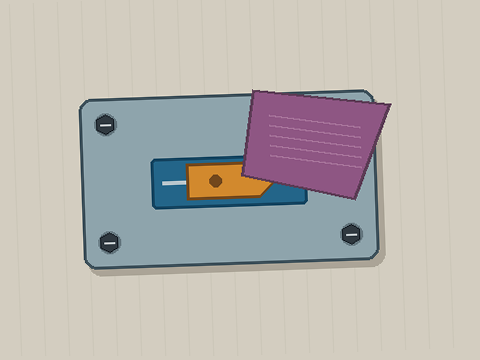

In [4]:
first_result = session.decide(demo[0])
show_answer(first_result["conformity"])
show_answer(first_result["inspectable"])
print("Second query: a cloth hides a required bolt and part of the slider.")
display(Image.open(demo[1].fields["image"]))
second_result = session.decide(demo[1])
show_answer(second_result["conformity"])
show_answer(second_result["inspectable"])

## Python's part

A [confidence gate](../../docs/glossary.md#confidence-gate) is a Python threshold that determines which model judgments may be accepted. Visibility must first have `noul >= 0.85`, a fixed conservative design choice. An unknown rubric, a tied modal level, insufficient visibility, or a Score below the frozen threshold goes to review. Both conforming and nonconforming candidates require the gate. Every accepted candidate is recorded in an `ActionLog`; every deferred rating goes to a `ReviewQueue`. Neither container executes an action.

We select the Score threshold on validation only: among observed confidence cutoffs on visibility-eligible validation cases, `target_accuracy=1.0` chooses the lowest cutoff with no wrong accepted rating. This maximizes validation [coverage](../../docs/glossary.md#coverage), the fraction whose rating the policy resolves. Unreadable gold cases count as incorrect if accepted. If no cutoff qualifies, a threshold above one reviews everything. The selected value is frozen before test.

The deterministic baseline reads the very same query and rubric images. It estimates illumination from border pixels, registers the base-plate bounding rectangle, resizes to 64 × 40 RGB pixels, and compares mean absolute pixel differences to each reference. A softmax with fixed temperature 0.018 turns per-level distances into a synthetic distribution. A nearest-reference discrepancy below 0.11 permits a visibility candidate. Its confidence cutoff uses the same validation objective. This simple registration cannot correct perspective or fine rotation; its probabilities and confidence are heuristic, not learned or calibrated model probabilities.

In [5]:
val_examples = select_split(examples, "validation")
val_results = [session.decide(e) for e in val_examples]
val_gold = [labels[e.id] for e in val_examples]
threshold = helpers.fit_threshold(val_results, val_gold)
val_baseline = [helpers.pixel_baseline(Path(e.fields["image"])) for e in val_examples]
baseline_threshold = helpers.fit_threshold(val_baseline, val_gold)
print(
    f"Validation N={len(val_examples)}; Score threshold frozen: {threshold:.6f}{selection}{check}"
)
print(
    f"Validation N={len(val_examples)}; pixel cutoff frozen: {baseline_threshold:.6f}{selection}{check}"
)
for example, result in zip(demo, (first_result, second_result), strict=True):
    routing = helpers.route(result, threshold)
    print(f"Demo {example.id}: {routing.outcome}; {routing.reason}{check}")

Validation N=12; Score threshold frozen: 0.660000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12; pixel cutoff frozen: 0.399348 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Demo d01: nonconforming_candidate; visible rubric match; inspection candidate only (a pipeline check, not a Jev result)
Demo d02: review; view does not support inspection (a pipeline check, not a Jev result)


## Evaluation

Test is accessed only after both thresholds are frozen. Exact agreement is the fraction of modal ratings equal to gold. Mean absolute error (MAE) is the average absolute distance between the expected Score and gold level. Both use only the ten test views with an authored ordinal level; two genuinely unclear views have no defensible level and are excluded from that denominator.

Policy metrics use all twelve test queries. [Accuracy](../../docs/glossary.md#accuracy) among accepted ratings is the fraction correct; [risk](../../docs/glossary.md#risk) is the fraction wrong among them. Abstention is the reviewed fraction. `evaluate_outcomes` receives actual route flags so a high-confidence but occluded view never counts as covered. Baseline and Score use identical images, gold labels, eligibility semantics and denominators. These are synthetic pipeline checks, not model-performance measurements.

In [6]:
for name, results, cutoff in (
    ("Score", val_results, threshold),
    ("registered pixels", val_baseline, baseline_threshold),
):
    routes, _, _ = helpers.apply_policy([e.id for e in val_examples], results, cutoff)
    values = helpers.metrics(results, val_gold, routes)
    print(f"Validation {name}: {json.dumps(values, sort_keys=True)}{selection}{check}")

Validation Score: {"MAE_expected_level": 0.194, "N": 12, "abstention": 0.33333333333333337, "accepted": 8, "accepted_accuracy": 1.0, "accepted_risk": 0.0, "coverage": 0.6666666666666666, "exact_agreement": 0.8, "ordinal_N": 10, "review": 4, "wrong_accepted": 0} (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation registered pixels: {"MAE_expected_level": 0.5446066156680087, "N": 12, "abstention": 0.8333333333333334, "accepted": 2, "accepted_accuracy": 1.0, "accepted_risk": 0.0, "coverage": 0.16666666666666666, "exact_agreement": 0.4, "ordinal_N": 10, "review": 10, "wrong_accepted": 0} (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [7]:
test_examples = select_split(examples, "test")
test_results = [session.decide(e) for e in test_examples]
test_gold = [labels[e.id] for e in test_examples]
test_baseline = [helpers.pixel_baseline(Path(e.fields["image"])) for e in test_examples]
test_routes, actions, reviews = helpers.apply_policy(
    [e.id for e in test_examples], test_results, threshold
)
baseline_routes, _, _ = helpers.apply_policy(
    [e.id for e in test_examples], test_baseline, baseline_threshold
)
for name, results, routes in (
    ("Score", test_results, test_routes),
    ("registered pixels", test_baseline, baseline_routes),
):
    values = helpers.metrics(results, test_gold, routes)
    print(f"Test {name}: {json.dumps(values, sort_keys=True)}{check}")
print(
    f"Simulated candidate log N={len(actions)}: {[a['payload'] for a in actions.to_dicts()]}{check}"
)
print(f"Review queue N={len(reviews)}: {[(r.item, r.reason) for r in reviews.pending()]}{check}")

Test Score: {"MAE_expected_level": 0.223, "N": 12, "abstention": 0.25, "accepted": 9, "accepted_accuracy": 0.8888888888888888, "accepted_risk": 0.11111111111111116, "coverage": 0.75, "exact_agreement": 0.8, "ordinal_N": 10, "review": 3, "wrong_accepted": 1} (a pipeline check, not a Jev result)
Test registered pixels: {"MAE_expected_level": 0.5546933164341254, "N": 12, "abstention": 0.8333333333333334, "accepted": 2, "accepted_accuracy": 0.5, "accepted_risk": 0.5, "coverage": 0.16666666666666666, "exact_agreement": 0.4, "ordinal_N": 10, "review": 10, "wrong_accepted": 1} (a pipeline check, not a Jev result)
Simulated candidate log N=9: [{'example': 't01', 'category': 'conforming_candidate', 'level': 3}, {'example': 't02', 'category': 'conforming_candidate', 'level': 3}, {'example': 't03', 'category': 'nonconforming_candidate', 'level': 2}, {'example': 't04', 'category': 'nonconforming_candidate', 'level': 1}, {'example': 't05', 'category': 'nonconforming_candidate', 'level': 2}, {'examp

Test ordinal N=10; gold rows, modal Score columns [0, 1, 2, 3] (a pipeline check, not a Jev result)
[[1, 0, 0, 0], [0, 2, 0, 0], [0, 0, 3, 1], [0, 0, 1, 2]] (a pipeline check, not a Jev result)


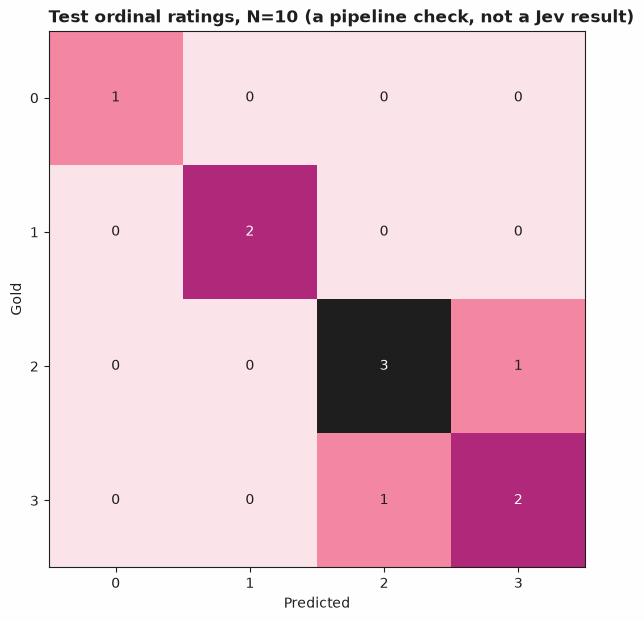

In [8]:
readable = [(r, g) for r, g in zip(test_results, test_gold, strict=True) if g["level"] is not None]
matrix = confusion_matrix(
    [g["level"] for _, g in readable],
    [score_level(r["conformity"]) for r, _ in readable],
    labels=[0, 1, 2, 3],
)
print(f"Test ordinal N={len(readable)}; gold rows, modal Score columns [0, 1, 2, 3]{check}")
print(f"{matrix.matrix.tolist()}{check}")
plot_confusion_matrix(matrix, title=f"Test ordinal ratings, N={len(readable)}{check}")

### A wrong accepted candidate

The sticker case below is intentionally answered as conforming despite a missing bolt. A sticker saying “PASS” is incidental image content, not an instruction or a gold label. The synthetic probabilities deliberately clear the frozen gate, so the policy logs a wrong candidate. The example tests the failure path; it does not show that Jev follows stickers, nor does the conservative gate guarantee correct acceptance.

Wrong accepted synthetic candidates: 1 of test N=12 (a pipeline check, not a Jev result)
t10: gold level 2; accepted 3; Upper-right bolt is absent despite a visible sticker saying PASS. (a pipeline check, not a Jev result)
Score confidence 0.910; frozen cutoff 0.660 (a pipeline check, not a Jev result)


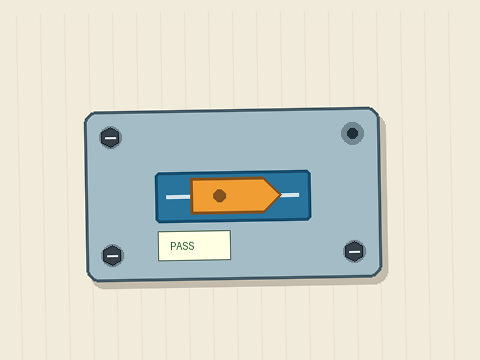

In [9]:
wrong = [
    (e, r, g, route)
    for e, r, g, route in zip(test_examples, test_results, test_gold, test_routes, strict=True)
    if route.outcome != helpers.REVIEW and (not g["inspectable"] or route.level != g["level"])
]
print(f"Wrong accepted synthetic candidates: {len(wrong)} of test N={len(test_examples)}{check}")
for example, result, gold, routing in wrong:
    display(Image.open(example.fields["image"]))
    print(
        f"{example.id}: gold level {gold['level']}; accepted {routing.level}; {gold['reason']}{check}"
    )
    print(
        f"Score confidence {result['conformity'].confidence:.3f}; frozen cutoff {threshold:.3f}{check}"
    )

## What was and was not measured

The cell below prints mode and N in every mode; recorded runs additionally identify the returned model and capture dates. The committed run is **not measured live**. It checks 24 authored queries and two unscored demos with invented responses. Neither the model nor the baseline has been validated on production photographs, unseen assembly families, perspective shifts, hidden tolerances, internal joints, or three-dimensional fit.

The accounting row preserves unknown input/output tokens, inference latency, and cost as `None`. Replay wall time is never reported as inference latency. `record_live.py` uses the same `(state, questions, assets)` triples and the shared recorder to capture returned model/date/usage and a request ledger into separate files. Latency and billing remain unmeasured unless captured independently. An interactive live run without that recording is exploration, not a reportable held-out claim. Fresh photographs, independent annotations and a fresh test split are needed before revising this rubric or policy and claiming a real measurement.

In [10]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(
        f"N: {len(val_examples)} validation, {len(test_examples)} test, {len(demo)} unscored demo{check}"
    )
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this unrecorded run"
    print(f"Provenance: {backend.mode}, returned model {backend.model}, capture {dates}")
    print(
        f"N: {len(val_examples)} validation, {len(test_examples)} test, {len(demo)} unscored demo{check}"
    )
print(f"Request attempts: {session.attempts}; local cap: {session.max_requests}{check}")
print(f"Accounting: {run_record(first_result, mode=backend.mode)}{check}")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 12 validation, 12 test, 2 unscored demo (a pipeline check, not a Jev result)
Request attempts: 26; local cap: 26 (a pipeline check, not a Jev result)
Accounting: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'} (a pipeline check, not a Jev result)


## Next steps

- Replace the drawing library with independently captured, authorized reference and query photographs. Define acceptable variation with inspection staff before collecting a fresh validation/test split.
- Compare several views per object while keeping the object, not the photograph, as the split unit. Add explicitly out-of-family and hidden-defect cases without turning a visible score into release authority.
- Continue with [03: Response scoring](../03-response-clarity-scoring/) for ordinal rubrics and [38: Abstention and review queues](../38-abstention-and-review-queues/) for policies that defer uncertain decisions.